In [1]:
from __future__ import annotations

from dataclasses import dataclass
from decimal import Decimal, ROUND_HALF_UP
from io import BytesIO
from pathlib import Path
from zipfile import ZipFile

import numpy as np
import pandas as pd
from IPython.display import display
from openpyxl.styles import Alignment, Font
from scipy.linalg import qr
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from scipy.stats import chi2, norm, t

ZIP_PATH = Path("Replication File.zip")
OUTPUT_PATH = Path("gone_for_good_results.xlsx")

In [2]:
class ReplicationArchive:
    """Read the original files directly from the ZIP."""

    def __init__(self, archive: ZipFile):
        self.archive = archive
        self.members = {
            Path(name).name: name for name in archive.namelist()
            if not name.endswith("/") and "__MACOSX" not in Path(name).parts
        }

    def read(self, name):
        return BytesIO(self.archive.read(self.members[name]))

    def stata(self, level):
        return pd.read_stata(self.read(f"{level}_level.dta"), convert_categoricals=False)


with ZipFile(ZIP_PATH) as zip_file:
    archive = ReplicationArchive(zip_file)
    county = archive.stata("county")
    individual = archive.stata("individual")
    anes = archive.stata("anes")

In [3]:
@dataclass(frozen=True)
class Model:
    table: str
    number: int
    level: str
    outcome: str
    controls: str
    endog: str = ""
    instruments: str = ""
    fixed_effects: str = ""
    cluster: str = ""
    year: int | None = None
    weight: str = ""
    method: str = "ivreg2"
    report: str = ""
    source_line: int = 0

COUNTY_CONTROLS = 'LAU_unemp_rate_4y pers_m_total_share_4y pers_coll_share_4y'
PANEL_CONTROLS = 'LAU_unemp_rate_4y it1 pers_m_total_share_4y_y1 pers_coll_share_4y_y1'
INDIVIDUAL_CONTROLS = (
    'white unempl_white i.gender gender_white i.educ educ_white age age_white '
    'i.approval_sen1 sen_white '
)
INDIVIDUAL_DEMOGRAPHICS = 'male_white coll_white white_counties_white'
ANES_CONTROLS = 'white_new gender unemployed college union ideology working_class_alignment'
RACE_CONTROLS1 = (
    'it_black_unempl it_his_unempl it_asian_unempl it_native_unempl it_mixed_unempl '
    'it_other_unempl it_me_unempl it_black_gender it_his_gender it_asian_gender '
    'it_native_gender it_mixed_gender it_other_gender it_me_gender it_black_age '
    'it_his_age it_asian_age it_native_age it_mixed_age it_other_age it_me_age '
    'it_black_educ it_his_educ it_asian_educ it_native_educ it_mixed_educ '
    'it_other_educ it_me_educ it_black_sen it_his_sen it_asian_sen it_native_sen '
    'it_mixed_sen it_other_sen it_me_sen '
)
RACE_CONTROLS2 = (
    'it_black_coll it_his_coll it_asian_coll it_native_coll it_mixed_coll '
    'it_other_coll it_me_coll it_black_male it_his_male it_asian_male it_native_male '
    'it_mixed_male it_other_male it_me_male it_black_whitec it_his_whitec '
    'it_asian_whitec it_native_whitec it_mixed_whitec it_other_whitec '
)
RACE_CONTROLS3 = (
    'it_black_serv it_his_serv it_asian_serv it_native_serv it_mixed_serv '
    'it_other_serv it_me_serv '
)
RACE_DUMMIES = 'race12 race13 race14 race15 race16 race17 race18'
RACE_LAYOFFS = 'it_black it_his it_asian it_native it_mixed it_other it_me'
RACE_INSTRUMENTS = (
    'it_black_instr it_his_instr it_asian_instr it_native_instr it_mixed_instr '
    'it_other_instr it_me_instr '
)

In [4]:
def group_codes(frame, names):
    return [pd.factorize(frame[name], sort=True)[0] for name in names]


def drop_singletons(frame, names):
    """Drop singleton groups as reghdfe does, iterating over multiple fixed effects."""
    while True:
        keep = np.ones(len(frame), dtype=bool)
        for codes in group_codes(frame, names):
            keep &= np.bincount(codes)[codes] > 1
        if keep.all():
            return frame
        frame = frame.loc[keep]


def dummy_matrix(codes, weights):
    rows = np.arange(len(codes))
    return csr_matrix((weights, (rows, codes)), shape=(len(codes), codes.max() + 1))


def within(values, groups, weights):
    """Project onto the orthogonal complement of the fixed effects using weights."""
    dummies = [dummy_matrix(codes, np.ones(len(codes))) for codes in groups]
    totals = [np.asarray(matrix.T @ weights) for matrix in dummies]
    transformed = values.copy()
    for _ in range(10_000):
        largest = 0.0
        for codes, matrix, total in zip(groups, dummies, totals):
            means = (matrix.T @ (weights[:, None] * transformed)) / total[:, None]
            transformed -= means[codes]
            largest = max(largest, np.abs(means).max())
        if largest < 1e-12:
            return transformed
    raise RuntimeError("The fixed-effects projection failed to converge.")


def fixed_effects_rank(groups):
    if len(groups) == 1:
        return int(groups[0].max() + 1)
    left, right = groups
    n_left, n_right = int(left.max() + 1), int(right.max() + 1)
    rows = np.r_[left, right + n_left]
    cols = np.r_[right + n_left, left]
    graph = csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(n_left + n_right,) * 2)
    return n_left + n_right - connected_components(graph, directed=False)[0]


def full_rank_columns(matrix, reference_norms=None):
    """Select linearly independent columns after normalizing their scale."""
    if matrix.shape[1] == 0:
        return np.array([], dtype=int)
    norms = np.linalg.norm(matrix, axis=0)
    if reference_norms is None:
        reference_norms = norms
    active = np.flatnonzero(norms > np.maximum(reference_norms, 1) * 1e-11)
    if not active.size:
        return active
    _, triangular, order = qr(matrix[:, active] / norms[active], mode="economic", pivoting=True)
    rank = np.count_nonzero(np.abs(triangular.diagonal()) > 1e-9)
    return np.sort(active[order[:rank]])

In [5]:
def score_covariance(scores, clusters):
    """Compute the sandwich meat using scores summed within each cluster."""
    if clusters is not None:
        scores = dummy_matrix(clusters, np.ones(len(clusters))).T @ scores
    return scores.T @ scores


def matrix_coefficients(names, beta, covariance, df=None):
    se = np.sqrt(np.diag(covariance).clip(min=0))
    statistic = np.divide(beta, se, out=np.full_like(beta, np.nan), where=se > 0)
    p_value = 2 * (norm.sf(abs(statistic)) if df is None else t.sf(abs(statistic), df))
    return pd.DataFrame(
        {"Coefficient": beta, "Standard error": se, "Test statistic": statistic, "p": p_value},
        index=pd.Index(names, name="Variable"),
    )


def first_stage_diagnostics(d, excluded, controls, clusters, q_small):
    """Compute Kleibergen–Paap rank tests after partialling out the controls.

    In these models the number of excluded instruments equals the number of
    endogenous regressors. The rank restriction concerns the smallest canonical
    correlation and has one degree of freedom.
    """
    if controls.shape[1]:
        q_controls, _ = np.linalg.qr(controls, mode="reduced")
        d = d - q_controls @ (q_controls.T @ d)
        excluded = excluded - q_controls @ (q_controls.T @ excluded)
    q_z, _ = np.linalg.qr(excluded, mode="reduced")
    q_d, _ = np.linalg.qr(d, mode="reduced")
    left, canonical, right_t = np.linalg.svd(q_z.T @ q_d, full_matrices=False)
    z_direction = q_z @ left[:, -1]
    d_direction = q_d @ right_t[-1]
    residual = d_direction - q_z @ (q_z.T @ d_direction)

    lm_meat = score_covariance((z_direction * d_direction)[:, None], clusters).item()
    wald_meat = score_covariance((z_direction * residual)[:, None], clusters).item()
    lm = canonical[-1] ** 2 / lm_meat
    wald = canonical[-1] ** 2 / wald_meat
    
    return lm, wald / (excluded.shape[1] * q_small)

In [7]:
def fit_model(data, model):
    """Estimate 2SLS using the specification in the authors' do-file."""
    controls = model.controls.split()
    endog = model.endog.split()
    excluded = model.instruments.split()
    effects = model.fixed_effects.split()
    factors = [name[2:] for name in controls if name.startswith("i.")]
    numeric = [name for name in controls if not name.startswith("i.")]
    group_vars = [*effects, model.cluster] if model.cluster else effects
    required = [model.outcome, *numeric, *factors, *endog, *excluded, *group_vars]
    if model.weight:
        required.append(model.weight)
    mask = pd.Series(True, index=data.index)
    if model.year is not None:
        mask &= data["year"].eq(model.year)
    if model.weight:
        mask &= data[model.weight].gt(0)
    if model.method == "xtivreg2":
        mask &= data["year"].ge(2008)
    sample = data.loc[mask, list(dict.fromkeys([*required, "year"]))].dropna(subset=required)
    if model.method == "ivreghdfe":
        sample = drop_singletons(sample, effects)
    elif model.method == "xtivreg2":
        sample = drop_singletons(sample, effects[:1])
    n = len(sample)
    weights = sample[model.weight].to_numpy(dtype=float, copy=True) if model.weight else np.ones(n)
    weights /= weights.mean()
    sqrt_w = np.sqrt(weights)[:, None]

    
    blocks = []
    names = []
    for term in controls:
        if term.startswith("i."):
            col = term[2:]
            levels = np.sort(sample[col].unique())[1:]
            blocks.append((sample[col].to_numpy()[:, None] == levels).astype(float))
            names.extend(f"{col}={level:g}" for level in levels)
        else:
            blocks.append(sample[[term]].to_numpy(dtype=float))
            names.append(term)
    control_matrix = np.column_stack(blocks)
    raw = np.column_stack([sample[model.outcome], control_matrix, sample[endog + excluded]])
    groups = group_codes(sample, effects)
    clusters = group_codes(sample, [model.cluster])[0] if model.cluster else None
    cluster_count = len(np.unique(clusters)) if clusters is not None else None

    transformed = within(raw, groups, weights)
    weighted = transformed * sqrt_w
    y = weighted[:, 0]
    control_end = 1 + len(names)
    c = weighted[:, 1:control_end]
    keep = full_rank_columns(c, np.linalg.norm(raw[:, 1:control_end] * sqrt_w, axis=0))
    c = c[:, keep]
    names = [names[i] for i in keep]
    d = weighted[:, control_end:control_end + len(endog)]
    z = weighted[:, control_end + len(endog):]
    x = np.column_stack([c, d])
    instruments = np.column_stack([c, z])
    q_z, _ = np.linalg.qr(instruments, mode="reduced")
    x_hat = q_z @ (q_z.T @ x)
    cross = x_hat.T @ x_hat
    beta, _, rank, _ = np.linalg.lstsq(q_z.T @ x, q_z.T @ y, rcond=1e-12)
    if rank != x.shape[1]:
        raise ValueError(f"Rank-deficient design matrix in Table {model.table}, model {model.number}.")
    error = y - x @ beta
    rss = error @ error
    k = x.shape[1]

    fe_rank = fixed_effects_rank(groups)
    if model.method == "ivreghdfe":
        
        df_adjust = 1
    elif model.method == "xtivreg2":
        
        df_adjust = fe_rank - np.unique(groups[0]).size
    else:
        df_adjust = fe_rank
    cluster_factor = cluster_count / (cluster_count - 1) if cluster_count else 1.0
    small = cluster_factor * (n - (1 if clusters is not None else 0)) / (n - k - df_adjust)
    bread = np.linalg.inv(cross)
    scores = x_hat * error[:, None]

    use_small = model.method == "ivreghdfe"
    vce_factor = small if use_small else 1.0

    covariance = (
        bread
        @ score_covariance(scores, clusters)
        @ bread
        * vce_factor
    )

    df = cluster_count - 1 if use_small else None

    coefs = matrix_coefficients(
        names + endog,
        beta,
        covariance,
        df,
    )
    lm, wald_f = first_stage_diagnostics(d, z, c, clusters, small)
    raw_y = raw[:, 0]
    raw_centered = raw_y - np.average(raw_y, weights=weights)
    tss = weights @ raw_centered**2 if model.method == "ivreghdfe" else y @ y
    return {
        "coefs": coefs,
        "N": n,
        "counties": cluster_count if cluster_count is not None else n,
        "R²": 1 - rss / tss,
        "underidentification": lm,
        "underidentification_p": chi2.sf(lm, 1),
        "weak_identification": wald_f,
    }

In [8]:
tables = {}

COUNT_ROWS = {"Employed", "Job losses", "Observations", "Number of counties"}
DECIMAL_ROWS = {"Employed share", "Job losses share", "R-squared"}

RACE_LABELS = ("Black", "Hispanic", "Asian", "Native", "Mixed", "Other", "Middle Eastern")
COEFFICIENT_LABELS = {
    "msl_pc4y2": "Manufacturing Layoffs",
    "msl_w_pc4y2": "White Manufacturing Layoffs",
    "msl_nw_pc4y2": "Non-white Manufacturing Layoffs",
    "it_new": "Manufacturing Layoffs × Dem. incumbent",
    "it_w2": "White Manufacturing Layoffs × Dem. incumbent",
    "it_nw2": "Non-white Manufacturing Layoffs × Dem. incumbent",
    "white": "White",
    "white_new": "White",
    "it_white": "White × Manufacturing Layoffs",
    "it5": "White × Manufacturing Layoffs",
    **dict(zip(RACE_DUMMIES.split(), RACE_LABELS)),
    **dict(zip(RACE_LAYOFFS.split(), [f"{race} × Manufacturing Layoffs" for race in RACE_LABELS])),
}

CONTROL_ROWS = {
    "2": ("Unemployment control", "Demography controls", "White population share",
          "Service layoffs", "State fixed effects"),
    "3": ("Unemployment control", "Individual controls", "Demography controls",
          "White population share", "Service layoffs", "County fixed effects"),
    "4": ("Unemployment control", "Individual controls", "Demography controls",
          "White population share", "Service layoffs", "County fixed effects"),
    "5": ("Individual controls", "District fixed effects"),
    "6": ("Unemployment control", "Demography controls", "White population share",
          "State fixed effects", "County fixed effects", "State-election fixed effects"),
    "7": ("Unemployment control", "Individual controls", "Demography controls",
          "White population share", "County fixed effects", "County-election fixed effects"),
}


def specification_flags(model):
    terms = set(model.controls.split())
    effects = set(model.fixed_effects.split())
    return {
        "Unemployment control": bool(terms & {"LAU_unemp_rate_4y", "unempl_white", "it_black_unempl"}),
        "Individual controls": bool(terms & {"i.gender", "it_black_gender", "gender"}),
        "Demography controls": bool(terms & {"pers_m_total_share_4y", "pers_m_total_share_4y_y1",
                                            "male_white", "it_black_male"}),
        "White population share": bool(terms & {"white_counties_4y", "white_counties_white",
                                               "it_black_whitec"}),
        "Service layoffs": bool(terms & {"msl_service_pc4y", "it_white_serv", "it_black_serv"}),
        "State fixed effects": "id_state" in effects,
        "District fixed effects": "id_district" in effects,
        "County fixed effects": "pan_id" in effects,
        "County-election fixed effects": "id_county_year" in effects,
        "State-election fixed effects": "id_state_year" in effects,
    }


def stars(p_value):
    return "***" if p_value < 0.01 else "**" if p_value < 0.05 else "*" if p_value < 0.10 else ""


def show_table(table, frame):
    tables[table] = frame
    shown = frame.astype(object).where(frame.notna(), "")
    for row in shown.index:
        if row in COUNT_ROWS:
            shown.loc[row] = shown.loc[row].map(
                lambda value: f"{Decimal(str(value)).quantize(Decimal('1'), rounding=ROUND_HALF_UP):,}"
            )
        elif row in DECIMAL_ROWS:
            shown.loc[row] = shown.loc[row].map(lambda value: f"{value:.3f}")
        elif row == "Weak identification test":
            shown.loc[row] = shown.loc[row].map(lambda value: f"{value:.2f}")
    display(shown)


def show_regression_table(models, data, coefficient_order, outcomes):
    table = models[0].table
    coefficient_digits = 3 if table in {"2", "6"} else 2
    columns = []
    for model, outcome in zip(models, outcomes, strict=True):
        result = fit_model(data, model)
        estimates = result["coefs"]
        rows = {"Estimator": "2SLS", "Outcome": outcome}
        if table in {"6", "7"}:
            rows["Election year(s)"] = model.year or "2008–2016"
        for term in coefficient_order:
            label = COEFFICIENT_LABELS[term]
            se_label = f"{label} (SE)"
            if term in model.report.split():
                estimate = estimates.loc[term]
                rows[label] = f"{estimate['Coefficient']:.{coefficient_digits}f}{stars(estimate['p'])}"
                rows[se_label] = f"({estimate['Standard error']:.3f})"
            else:
                rows[label], rows[se_label] = None, None
        if table in {"3", "4", "6", "7"}:
            rows["Number of counties"] = result["counties"]
        rows["Observations"] = result["N"]
        rows["R-squared"] = result["R²"]
        rows["Underidentification test"] = (
            f"{result['underidentification']:.2f}{stars(result['underidentification_p'])}"
        )
        rows["Weak identification test"] = result["weak_identification"]
        flags = specification_flags(model)
        rows.update({label: "Yes" if flags[label] else "No" for label in CONTROL_ROWS[table]})
        columns.append(pd.Series(rows, name=f"({model.number})"))
    show_table(table, pd.concat(columns, axis=1))

In [9]:
def table_1(archive):
    race_labels = [
        "White", "Black", "Native American", "Asian", "Pacific Islander",
        "Two or more race groups", "Hispanic or Latino",
    ]
    results = {}
    for sheet, label in (("employment_race", "Employed"), ("layoffs_race", "Job losses")):
        frame = pd.read_excel(archive.read("Table 1.xlsx"), sheet_name=sheet, header=None)
        years = pd.to_numeric(frame.iloc[:, 0], errors="coerce")
        values = frame.loc[years.between(2012, 2015), 1:7].astype(float)
        if len(values) != 4 or values.isna().any().any():
            raise ValueError(f"{sheet}: Expected four complete years of data.")
        mean = values.mean().to_numpy()
        results[label] = mean
        # We should note tha there, Hispanic or Latino ethnicity overlaps the race categories.
        results[f"{label} share"] = mean / mean[:6].sum()
    return pd.DataFrame(results, index=race_labels).T

with ZipFile(ZIP_PATH) as zip_file:
    show_table("1", table_1(ReplicationArchive(zip_file)))

,White,Black,Native American,Asian,Pacific Islander,Two or more race groups,Hispanic or Latino
Employed,"9,887,194","1,197,335","106,496","772,880","27,029","161,081","1,779,685"
Employed share,0.814,0.099,0.009,0.064,0.002,0.013,0.146
Job losses,"253,064","43,544","7,098","24,842","1,784","10,173","68,439"
Job losses share,0.743,0.128,0.021,0.073,0.005,0.030,0.201


In [10]:
models_2 = (
    Model('2', 1, 'county', 'ddem_votes_pct1', COUNTY_CONTROLS,
          endog='msl_pc4y2', instruments='bartik_leo5', year=2016, fixed_effects='id_state',
          report='msl_pc4y2', source_line=39),
    Model('2', 2, 'county', 'ddem_votes_pct1', f'{COUNTY_CONTROLS} white_counties_4y',
          endog='msl_pc4y2', instruments='bartik_leo5', year=2016, fixed_effects='id_state',
          report='msl_pc4y2', source_line=42),
    Model('2', 3, 'county', 'ddem_votes_pct1', f'{COUNTY_CONTROLS} white_counties_4y msl_service_pc4y',
          endog='msl_pc4y2', instruments='bartik_leo5', year=2016, fixed_effects='id_state',
          report='msl_pc4y2', source_line=45),
    Model('2', 4, 'county', 'ddem_votes_pct1', f'{COUNTY_CONTROLS} msl_nw_pc4y2',
          endog='msl_w_pc4y2', instruments='bartik_leo5_w2', year=2016, fixed_effects='id_state',
          report='msl_w_pc4y2 msl_nw_pc4y2', source_line=48),
    Model('2', 5, 'county', 'ddem_votes_pct1', f'{COUNTY_CONTROLS} white_counties_4y msl_nw_pc4y2',
          endog='msl_w_pc4y2', instruments='bartik_leo5_w2', year=2016, fixed_effects='id_state',
          report='msl_w_pc4y2 msl_nw_pc4y2', source_line=51),
    Model('2', 6, 'county', 'ddem_votes_pct1', f'{COUNTY_CONTROLS} white_counties_4y msl_service_pc4y msl_nw_pc4y2',
          endog='msl_w_pc4y2', instruments='bartik_leo5_w2', year=2016, fixed_effects='id_state',
          report='msl_w_pc4y2 msl_nw_pc4y2', source_line=54),
)

show_regression_table(
    models_2, county,
    ('msl_pc4y2', 'msl_w_pc4y2', 'msl_nw_pc4y2'),
    ["Change of Democratic Vote Share"] * 6,
)

,(1),(2),(3),(4),(5),(6)
Estimator,2SLS,2SLS,2SLS,2SLS,2SLS,2SLS
Outcome,Change of Democratic Vote Share,Change of Democratic Vote Share,Change of Democratic Vote Share,Change of Democratic Vote Share,Change of Democratic Vote Share,Change of Democratic Vote Share
Manufacturing Layoffs,-0.066***,-0.044**,-0.043**,,,
Manufacturing Layoffs (SE),(0.019),(0.018),(0.019),,,
White Manufacturing Layoffs,,,,-0.234***,-0.145***,-0.151***
White Manufacturing Layoffs (SE),,,,(0.033),(0.035),(0.036)
Non-white Manufacturing Layoffs,,,,0.185***,0.131***,0.132***
Non-white Manufacturing Layoffs (SE),,,,(0.034),(0.032),(0.032)
Observations,"3,068","3,066","3,065","2,767","2,766","2,765"
R-squared,0.500,0.539,0.539,0.564,0.589,0.589


In [11]:
models_3 = (
    Model('3', 1, 'individual', 'vote_dem', INDIVIDUAL_CONTROLS,
          endog='it_white', instruments='it_white_instr', year=2016, fixed_effects='pan_id',
          cluster='pan_id', method='ivreghdfe', report='white it_white', source_line=65),
    Model('3', 2, 'individual', 'vote_dem', f'{INDIVIDUAL_CONTROLS} {INDIVIDUAL_DEMOGRAPHICS}',
          endog='it_white', instruments='it_white_instr', year=2016, fixed_effects='pan_id',
          cluster='pan_id', method='ivreghdfe', report='white it_white', source_line=68),
    Model('3', 3, 'individual', 'vote_dem', f'{INDIVIDUAL_CONTROLS} {INDIVIDUAL_DEMOGRAPHICS} it_white_serv',
          endog='it_white', instruments='it_white_instr', year=2016, fixed_effects='pan_id',
          cluster='pan_id', method='ivreghdfe', report='white it_white', source_line=71),
    Model('3', 4, 'individual', 'voting', INDIVIDUAL_CONTROLS,
          endog='it_white', instruments='it_white_instr', year=2016, fixed_effects='pan_id',
          cluster='pan_id', method='ivreghdfe', report='white it_white', source_line=74),
)

show_regression_table(
    models_3, individual,
    ('white', 'it_white'),
    ["Pr(Voting for Clinton = 1)"] * 3 + ["Pr(Voting = 1)"],
)

,(1),(2),(3),(4)
Estimator,2SLS,2SLS,2SLS,2SLS
Outcome,Pr(Voting for Clinton = 1),Pr(Voting for Clinton = 1),Pr(Voting for Clinton = 1),Pr(Voting = 1)
White,0.18***,-0.32***,-0.33***,0.20***
White (SE),(0.042),(0.093),(0.091),(0.036)
White × Manufacturing Layoffs,-0.64***,-0.67**,-0.51*,0.71**
White × Manufacturing Layoffs (SE),(0.230),(0.267),(0.281),(0.305)
Number of counties,"2,233","2,232","2,231","2,233"
Observations,"63,605","63,591","63,582","63,605"
R-squared,0.165,0.166,0.166,0.151
Underidentification test,206.04***,139.70***,134.69***,206.04***


In [12]:
models_4 = (
    Model('4', 1, 'individual', 'vote_dem', f'{RACE_CONTROLS1} {RACE_DUMMIES}',
          endog=RACE_LAYOFFS, instruments=RACE_INSTRUMENTS, year=2016, fixed_effects='pan_id',
          cluster='pan_id', method='ivreghdfe', report=f'{RACE_DUMMIES} {RACE_LAYOFFS}', source_line=82),
    Model('4', 2, 'individual', 'vote_dem', f'{RACE_CONTROLS1} {RACE_CONTROLS2} {RACE_DUMMIES}',
          endog=RACE_LAYOFFS, instruments=RACE_INSTRUMENTS, year=2016, fixed_effects='pan_id',
          cluster='pan_id', method='ivreghdfe', report=f'{RACE_DUMMIES} {RACE_LAYOFFS}', source_line=85),
    Model('4', 3, 'individual', 'vote_dem', f'{RACE_CONTROLS1} {RACE_CONTROLS2} {RACE_CONTROLS3} {RACE_DUMMIES}',
          endog=RACE_LAYOFFS, instruments=RACE_INSTRUMENTS, year=2016, fixed_effects='pan_id',
          cluster='pan_id', method='ivreghdfe', report=f'{RACE_DUMMIES} {RACE_LAYOFFS}', source_line=88),
    Model('4', 4, 'individual', 'voting', f'{RACE_CONTROLS1} {RACE_DUMMIES}',
          endog=RACE_LAYOFFS, instruments=RACE_INSTRUMENTS, year=2016, fixed_effects='pan_id',
          cluster='pan_id', method='ivreghdfe', report=f'{RACE_DUMMIES} {RACE_LAYOFFS}', source_line=91),
)

show_regression_table(
    models_4, individual,
    (RACE_DUMMIES + ' ' + RACE_LAYOFFS).split(),
    ["Pr(Voting for Clinton = 1)"] * 3 + ["Pr(Voting = 1)"],
)

,(1),(2),(3),(4)
Estimator,2SLS,2SLS,2SLS,2SLS
Outcome,Pr(Voting for Clinton = 1),Pr(Voting for Clinton = 1),Pr(Voting for Clinton = 1),Pr(Voting = 1)
Black,-0.62***,-0.09,-0.08,-0.75***
Black (SE),(0.050),(0.142),(0.141),(0.047)
Hispanic,-0.33***,0.06,0.07,-0.59***
Hispanic (SE),(0.053),(0.130),(0.129),(0.048)
Asian,-0.30***,-0.21,-0.20,-0.40***
Asian (SE),(0.080),(0.204),(0.201),(0.079)
Native,-0.22,-0.07,0.03,-0.35**
Native (SE),(0.139),(0.293),(0.297),(0.153)


In [13]:
models_5 = (
    Model('5', 1, 'anes', 'econ_worse', ANES_CONTROLS,
          endog='it5', instruments='it_instr5', weight='V160101w', fixed_effects='id_district',
          report='white_new it5', source_line=37),
    Model('5', 2, 'anes', 'rightwrong_track_recoded', ANES_CONTROLS,
          endog='it5', instruments='it_instr5', weight='V160101w', fixed_effects='id_district',
          report='white_new it5', source_line=40),
    Model('5', 3, 'anes', 'opportunity_ahead_rec', ANES_CONTROLS,
          endog='it5', instruments='it_instr5', weight='V160101w', fixed_effects='id_district',
          report='white_new it5', source_line=43),
    Model('5', 4, 'anes', 'negecon', ANES_CONTROLS,
          endog='it5', instruments='it_instr5', weight='V160101w', fixed_effects='id_district',
          report='white_new it5', source_line=46),
)

show_regression_table(
    models_5, anes,
    ('white_new', 'it5'),
    ["US economy better than previous years", "Things in the US on the right track",
     "Opportunity in the US to get ahead", "You and your family better financially than previous years"],
)

,(1),(2),(3),(4)
Estimator,2SLS,2SLS,2SLS,2SLS
Outcome,US economy better than previous years,Things in the US on the right track,Opportunity in the US to get ahead,You and your family better financially than pr...
White,0.13,0.07,0.15,-0.05
White (SE),(0.088),(0.098),(0.103),(0.084)
White × Manufacturing Layoffs,-3.73***,-2.83*,-3.97**,0.79
White × Manufacturing Layoffs (SE),(1.435),(1.678),(1.693),(1.404)
Observations,"1,686","1,685","1,449","1,686"
R-squared,0.119,0.168,0.044,0.085
Underidentification test,115.60***,114.45***,96.12***,115.60***
Weak identification test,277.10,273.14,186.55,277.10


In [14]:
models_6 = (
    Model('6', 1, 'county', 'ddem_votes_pct1', f'{PANEL_CONTROLS} white_counties_4y white_counties_4y_y1',
          endog='msl_pc4y2 it_new', instruments='bartik_leo5 it_instr2',
          fixed_effects='pan_id id_state_year', cluster='pan_id', method='xtivreg2',
          report='msl_pc4y2 it_new', source_line=59),
    Model('6', 2, 'county', 'ddem_votes_pct1', f'{PANEL_CONTROLS} white_counties_4y white_counties_4y_y1 msl_nw_pc4y2 it_nw2',
          endog='msl_w_pc4y2 it_w2', instruments='bartik_leo5_w2 it_w2_instr_new',
          fixed_effects='pan_id id_state_year', cluster='pan_id', method='xtivreg2',
          report='msl_w_pc4y2 it_w2 msl_nw_pc4y2 it_nw2', source_line=62),
    Model('6', 3, 'county', 'ddem_votes_pct1', f'{COUNTY_CONTROLS} msl_nw_pc4y2',
          endog='msl_w_pc4y2', instruments='bartik_leo5_w2', year=2008, fixed_effects='id_state',
          report='msl_nw_pc4y2 msl_w_pc4y2', source_line=65),
    Model('6', 4, 'county', 'ddem_votes_pct1', f'{COUNTY_CONTROLS} msl_nw_pc4y2',
          endog='msl_w_pc4y2', instruments='bartik_leo5_w2', year=2012, fixed_effects='id_state',
          report='msl_nw_pc4y2 msl_w_pc4y2', source_line=68),
)

show_regression_table(
    models_6, county,
    ('msl_pc4y2', 'msl_w_pc4y2', 'msl_nw_pc4y2', 'it_new', 'it_w2', 'it_nw2'),
    ["Change of Democratic Vote Share"] * 4,
)

,(1),(2),(3),(4)
Estimator,2SLS,2SLS,2SLS,2SLS
Outcome,Change of Democratic Vote Share,Change of Democratic Vote Share,Change of Democratic Vote Share,Change of Democratic Vote Share
Election year(s),2008–2016,2008–2016,2008,2012
Manufacturing Layoffs,0.154***,,,
Manufacturing Layoffs (SE),(0.037),,,
White Manufacturing Layoffs,,0.264***,-0.018,-0.102***
White Manufacturing Layoffs (SE),,(0.054),(0.024),(0.019)
Non-white Manufacturing Layoffs,,-0.144***,0.092***,0.103***
Non-white Manufacturing Layoffs (SE),,(0.035),(0.022),(0.017)
Manufacturing Layoffs × Dem. incumbent,-0.044**,,,


In [15]:
models_7 = (
    Model('7', 1, 'individual', 'vote_dem', f'{INDIVIDUAL_CONTROLS} {INDIVIDUAL_DEMOGRAPHICS}',
          endog='it_white', instruments='it_white_instr', fixed_effects='id_county_year',
          cluster='pan_id', method='ivreghdfe', report='white it_white', source_line=96),
    Model('7', 2, 'individual', 'vote_dem', INDIVIDUAL_CONTROLS,
          endog='it_white', instruments='it_white_instr', year=2008, fixed_effects='pan_id',
          cluster='pan_id', method='ivreghdfe', report='white it_white', source_line=99),
    Model('7', 3, 'individual', 'vote_dem', INDIVIDUAL_CONTROLS,
          endog='it_white', instruments='it_white_instr', year=2012, fixed_effects='pan_id',
          cluster='pan_id', method='ivreghdfe', report='white it_white', source_line=102),
)

show_regression_table(
    models_7, individual,
    ('white', 'it_white'),
    ["Pr(Voting for the Democratic Candidate = 1)"] * 3,
)

,(1),(2),(3)
Estimator,2SLS,2SLS,2SLS
Outcome,Pr(Voting for the Democratic Candidate = 1),Pr(Voting for the Democratic Candidate = 1),Pr(Voting for the Democratic Candidate = 1)
Election year(s),2008–2016,2008,2012
White,-0.38***,0.00,0.21***
White (SE),(0.053),(0.058),(0.041)
White × Manufacturing Layoffs,-0.49***,-0.41,-0.39*
White × Manufacturing Layoffs (SE),(0.176),(0.281),(0.225)
Number of counties,"2,545","1,968","2,200"
Observations,"146,117","30,500","52,055"
R-squared,0.153,0.139,0.161


In [16]:
table_order = [str(number) for number in range(1, 8)]
missing_tables = [number for number in table_order if number not in tables]
if missing_tables:
    raise RuntimeError(f"Run these table cells before exporting: {', '.join(missing_tables)}.")

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
with pd.ExcelWriter(OUTPUT_PATH, engine="openpyxl") as writer:
    for number in table_order:
        name = f"Table {number}"
        tables[number].to_excel(writer, sheet_name=name)
        sheet = writer.sheets[name]
        sheet.freeze_panes = "B2"
        sheet.column_dimensions["A"].width = 54
        for column in sheet.iter_cols(min_col=2):
            sheet.column_dimensions[column[0].column_letter].width = 18 if number == "1" else 20
            column[0].alignment = Alignment(wrap_text=True)
            for cell in column[1:]:
                row_label = sheet.cell(cell.row, 1).value
                if row_label in {"Estimator", "Outcome", "Election year(s)"}:
                    cell.alignment = Alignment(wrap_text=True, vertical="center")
                if row_label in {"Employed", "Job losses", "Observations", "Number of counties"}:
                    cell.number_format = "#,##0"
                elif row_label == "Weak identification test":
                    cell.number_format = "0.00"
                elif row_label == "R-squared" or number == "1":
                    cell.number_format = "0.000"
        sheet.row_dimensions[1].height = 30 if number == "1" else 16
        if number != "1":
            sheet.row_dimensions[3].height = 56 if number == "5" else 32
        for cell in sheet[1]:
            cell.font = Font(bold=True)

print(f"Saved Tables 1–7 to {OUTPUT_PATH.resolve()}")

Saved Tables 1–7 to /Users/TjarkBeier/Desktop/Studium/MSc/UZH/Sem1/Empirical Methods/Problem Sets/03 & 04/gone_for_good_results.xlsx


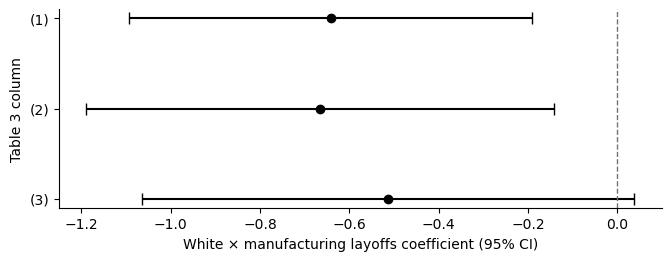

In [17]:
import matplotlib.pyplot as plt
from scipy.stats import t

term = "it_white"  # White × Manufacturing Layoffs
estimates, margins, labels = [], [], []

for model in models_3[:3]:
    result = fit_model(individual, model)
    coefficients = result["coefs"]
    estimate = coefficients.loc[term, "Coefficient"]
    se = coefficients.loc[term, "Standard error"]

    df = result["N"] - len(coefficients) - result["counties"]
    estimates.append(estimate)
    margins.append(t.ppf(0.975, df) * se)
    labels.append(f"({model.number})")

fig, ax = plt.subplots(figsize=(6.6, 2.5), layout="constrained")
positions = range(len(labels))

ax.errorbar(
    estimates, positions, xerr=margins, fmt="o",
    color="black", capsize=4, markersize=6,
)
ax.axvline(0, color="0.45", linestyle="--", linewidth=1)
ax.set_yticks(positions, labels)
ax.invert_yaxis()
ax.set_ylabel("Table 3 column")
ax.set_xlabel("White × manufacturing layoffs coefficient (95% CI)")
ax.spines[["top", "right"]].set_visible(False)

fig.savefig("table3_clinton_coefficients.pdf", bbox_inches="tight")
plt.show()

,(1),(2),(3),(4)
Estimator,2SLS,2SLS,2SLS,2SLS
Outcome,Pr(Voting for Clinton = 1),Pr(Voting for Clinton = 1),Pr(Voting for Clinton = 1),Pr(Voting = 1)
White,0.18***,-0.32***,-0.33***,0.20***
White (SE),(0.042),(0.093),(0.091),(0.036)
White × Manufacturing Layoffs,-0.64***,-0.67**,-0.51*,0.71**
White × Manufacturing Layoffs (SE),(0.230),(0.267),(0.281),(0.305)
Number of counties,"2,233","2,232","2,231","2,233"
Observations,"63,605","63,591","63,582","63,605"
R-squared,0.165,0.166,0.166,0.151
Underidentification test,206.04***,139.70***,134.69***,206.04***


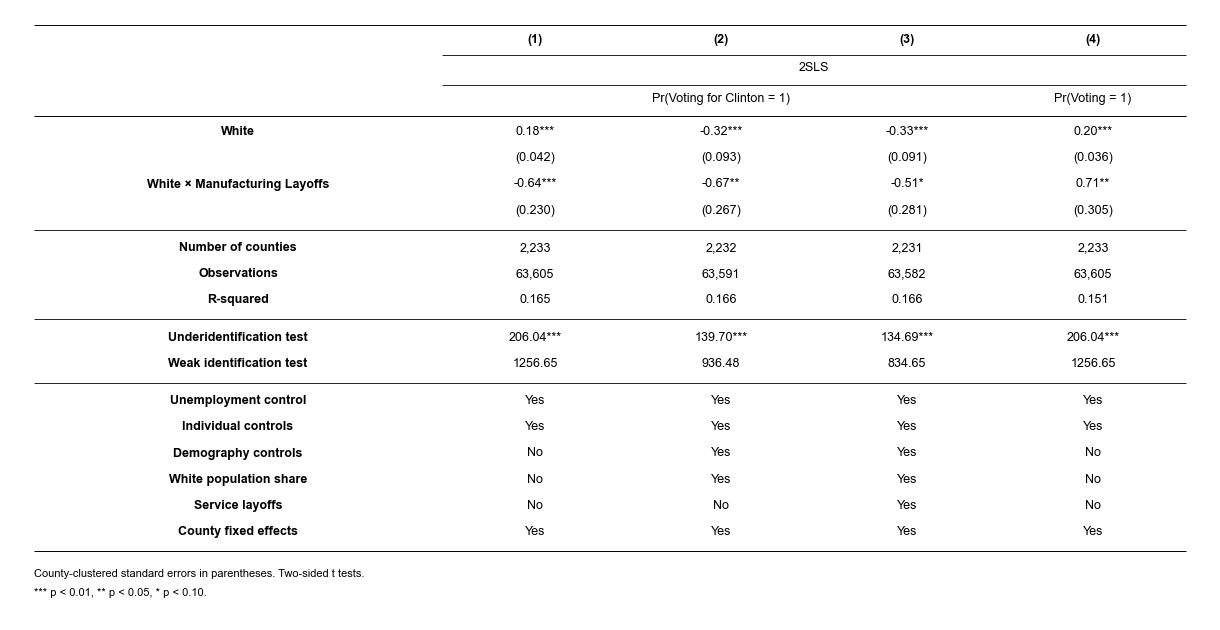

Saved /Users/TjarkBeier/Desktop/Studium/MSc/UZH/Sem1/Empirical Methods/Problem Sets/03 & 04/gone_for_good_replicationTable3.png


In [18]:
from pathlib import Path
import matplotlib.pyplot as plt

show_regression_table(
    models_3,
    individual,
    ("white", "it_white"),
    ["Pr(Voting for Clinton = 1)"] * 3 + ["Pr(Voting = 1)"],
)

table3 = tables["3"].copy()
formatted = table3.astype(str)

for label in ["Observations", "Number of counties"]:
    formatted.loc[label] = table3.loc[label].map(
        lambda value: f"{int(value):,}"
    )

for label, digits in [
    ("R-squared", 3),
    ("Weak identification test", 2),
]:
    formatted.loc[label] = table3.loc[label].map(
        lambda value: f"{float(value):.{digits}f}"
    )

body = formatted.drop(index=["Estimator", "Outcome"])

left, numeric_left, right = 0.02, 0.36, 0.98
column_width = (right - numeric_left) / 4

centers = [
    numeric_left + column_width * (i + 0.5)
    for i in range(4)
]

with plt.rc_context({
    "font.family": "sans-serif",
    "font.sans-serif": [
        "Calibri", "Carlito", "Arial", "DejaVu Sans"
    ],
    "font.size": 9,
}):
    fig = plt.figure(figsize=(12, 6.1))
    ax = fig.add_axes([0, 0, 1, 1])

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    # we set the correct Column numbers.
    ax.hlines(
        0.975, left, right,
        color="black", linewidth=0.7,
    )

    for x, label in zip(centers, table3.columns):
        ax.text(
            x, 0.951, label,
            ha="center", va="center", weight="bold",
        )

    # Estimator and outcomes.
    ax.hlines(
        0.927, numeric_left, right,
        color="black", linewidth=0.6,
    )

    ax.text(
        (numeric_left + right) / 2,
        0.900,
        "2SLS",
        ha="center",
    )

    ax.hlines(
        0.877, numeric_left, right,
        color="black", linewidth=0.6,
    )

    ax.text(
        centers[1], 0.849,
        "Pr(Voting for Clinton = 1)",
        ha="center",
    )

    ax.text(
        centers[3], 0.849,
        "Pr(Voting = 1)",
        ha="center",
    )

    ax.hlines(
        0.827, left, right,
        color="black", linewidth=0.7,
    )

    # Coeffs, SEs and and some diagnostics .
    y = 0.800

    section_starts = {
        "Number of counties",
        "Underidentification test",
        "Unemployment control",
    }

    for label, values in body.iterrows():
        if label in section_starts:
            ax.hlines(
                y + 0.012, left, right,
                color="black", linewidth=0.6,
            )
            y -= 0.018

        row_label = "" if label.endswith("(SE)") else label

        ax.text(
            (left + numeric_left) / 2,
            y,
            row_label,
            ha="center",
            va="center",
            weight="bold",
        )

        for x, value in zip(centers, values):
            ax.text(
                x, y, value,
                ha="center", va="center",
            )

        y -= 0.043

    ax.hlines(
        y + 0.012, left, right,
        color="black", linewidth=0.7,
    )

    ax.text(
        left,
        y - 0.018,
        "County-clustered standard errors in parentheses. "
        "Two-sided t tests.",
        fontsize=8,
        va="top",
    )

    ax.text(
        left,
        y - 0.048,
        "*** p < 0.01, ** p < 0.05, * p < 0.10.",
        fontsize=8,
        va="top",
    )

    output_png = Path("gone_for_good_replicationTable3.png")

    fig.savefig(
        output_png,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.05,
    )

    plt.show()

print(f"Saved {output_png.resolve()}")

In [19]:
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import t
from IPython.display import display

EXTENSION_DIR = Path("state_white_extension_outputs")
EXTENSION_DIR.mkdir(parents=True, exist_ok=True)

baseline_spec = replace(models_3[2], table="Extension", number=1)

required = [
    baseline_spec.outcome,
    baseline_spec.endog,
    baseline_spec.instruments,
    "pan_id",
    "state_fips",
    "year",
    "msl_pc4y2",
    *[
        term.removeprefix("i.")
        for term in baseline_spec.controls.split()
    ],
]

extension_sample = individual.loc[
    individual["year"].eq(2016)
].dropna(subset=required).copy()

extension_sample = drop_singletons(
    extension_sample, ["pan_id"]
)

if extension_sample.groupby("pan_id")["state_fips"].nunique().max() != 1:
    raise ValueError("Each county must belong to one state.")

# Keep White and omit one state interaction to avoid multicollinearity.
state_counts = extension_sample.groupby("state_fips").size()
reference_state = state_counts.idxmax()

state_white_terms = []

for state in sorted(state_counts.index):
    if state == reference_state:
        continue

    term = f"white_state_{int(state)}"

    extension_sample[term] = (
        extension_sample["white"]
        * extension_sample["state_fips"].eq(state).astype(float)
    )

    state_white_terms.append(term)

extended_spec = replace(
    baseline_spec,
    number=2,
    controls=(
        baseline_spec.controls
        + " "
        + " ".join(state_white_terms)
    ),
)

print(f"Reference state FIPS: {int(reference_state)}")
print(
    f"Common sample: {len(extension_sample):,} respondents "
    f"in {extension_sample['pan_id'].nunique():,} counties"
)

Reference state FIPS: 6
Common sample: 63,582 respondents in 2,231 counties


In [20]:
extension_results = {
    "Baseline": fit_model(extension_sample, baseline_spec),
    "State x White": fit_model(extension_sample, extended_spec),
}

summary_rows = []
full_coefficients = []

for label, result in extension_results.items():
    coefficients = result["coefs"].copy()

    # County-clustered t inference.
    critical = t.ppf(0.975, result["counties"] - 1)

    coefficients["95% CI lower"] = (
        coefficients["Coefficient"]
        - critical * coefficients["Standard error"]
    )

    coefficients["95% CI upper"] = (
        coefficients["Coefficient"]
        + critical * coefficients["Standard error"]
    )

    coefficients.insert(0, "Model", label)
    full_coefficients.append(coefficients.reset_index())

    interaction = coefficients.loc["it_white"]

    summary_rows.append({
        "Model": label,
        "Coefficient": interaction["Coefficient"],
        "Clustered SE": interaction["Standard error"],
        "p-value": interaction["p"],
        "95% CI lower": interaction["95% CI lower"],
        "95% CI upper": interaction["95% CI upper"],
        "Observations": result["N"],
        "Counties": result["counties"],
        "R-squared": result["R²"],
        "KP rk Wald F": result["weak_identification"],
        "KP rk LM": result["underidentification"],
        "KP rk LM p-value": result["underidentification_p"],
    })

extension_summary = (
    pd.DataFrame(summary_rows)
    .set_index("Model")
)

extension_coefficients = pd.concat(
    full_coefficients,
    ignore_index=True,
)

display(extension_summary.round(4).T)

extension_summary.to_csv(
    EXTENSION_DIR / "interaction_results.csv"
)

extension_coefficients.to_csv(
    EXTENSION_DIR / "all_coefficients.csv",
    index=False,
)

print(
    "All coefficients, clustered standard errors, p-values "
    "and confidence intervals are saved in all_coefficients.csv."
)

print(
    "In the extended model, the White coefficient refers "
    "to the reference state at zero values of its interacted covariates."
)

Model,Baseline,State x White
Coefficient,-0.5130,-0.0492
Clustered SE,0.2812,0.2827
p-value,0.0682,0.8619
95% CI lower,-1.0644,-0.6035
95% CI upper,0.0385,0.5051
Observations,63582.0000,63582.0000
Counties,2231.0000,2231.0000
R-squared,0.1662,0.1686
KP rk Wald F,834.6499,601.6570
KP rk LM,134.6900,132.5834


All coefficients, clustered standard errors, p-values and confidence intervals are saved in all_coefficients.csv.
In the extended model, the White coefficient refers to the reference state at zero values of its interacted covariates.


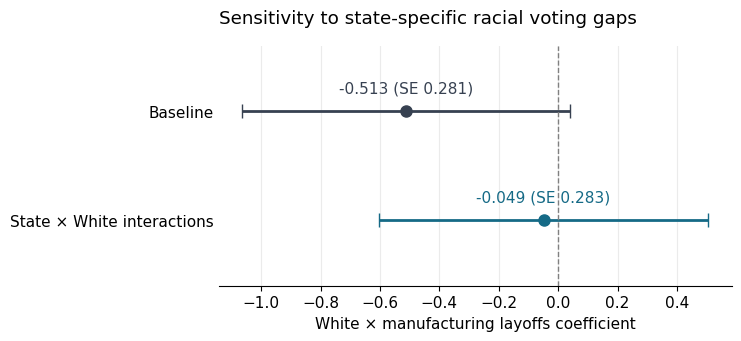

In [21]:
plot_colors = ["#374151", "#156a86"]

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
}):
    fig, ax = plt.subplots(
        figsize=(7.3, 3.3),
        layout="constrained",
    )

    for position, ((label, row), color) in enumerate(
        zip(extension_summary.iterrows(), plot_colors)
    ):
        margin = row["95% CI upper"] - row["Coefficient"]

        ax.errorbar(
            row["Coefficient"],
            position,
            xerr=margin,
            fmt="o",
            color=color,
            markersize=8,
            capsize=5,
            elinewidth=2,
        )

        ax.annotate(
            f"{row['Coefficient']:.3f} "
            f"(SE {row['Clustered SE']:.3f})",
            (row["Coefficient"], position),
            xytext=(0, 13),
            textcoords="offset points",
            ha="center",
            color=color,
        )

    ax.axvline(
        0,
        color="0.5",
        linewidth=1,
        linestyle="--",
    )

    ax.set_yticks(
        [0, 1],
        ["Baseline", "State × White interactions"],
    )

    ax.set_ylim(1.6, -0.6)

    ax.set_xlabel(
        "White × manufacturing layoffs coefficient"
    )

    ax.set_title(
        "Sensitivity to state-specific racial voting gaps",
        loc="left",
        pad=16,
    )

    ax.grid(axis="x", color="0.92")
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)

    fig.savefig(
        EXTENSION_DIR / "figure1_interaction_comparison.pdf",
        bbox_inches="tight",
    )

    fig.savefig(
        EXTENSION_DIR / "figure1_interaction_comparison.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

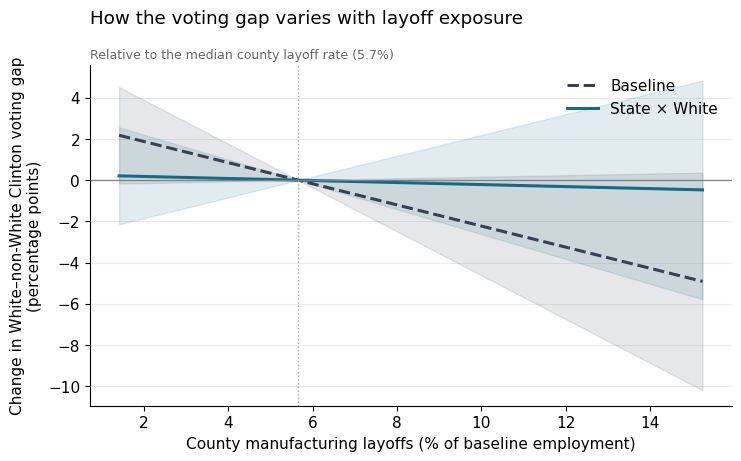

In [22]:
# Count each county once when calculating the plotting range.
county_layoffs = extension_sample.drop_duplicates(
    "pan_id"
)["msl_pc4y2"]

reference_rate = county_layoffs.median()
lower_rate, upper_rate = county_layoffs.quantile([0.05, 0.95])

rate_grid = np.sort(
    np.unique(
        np.r_[
            np.linspace(lower_rate, upper_rate, 200),
            reference_rate,
        ]
    )
)

# Layoff rates are proportions.
# Multiplying the predicted probability change by 100 hence gives pps.
difference_pp = (rate_grid - reference_rate) * 100

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
}):
    fig, ax = plt.subplots(
        figsize=(7.3, 4.5),
        layout="constrained",
    )

    for (label, row), color, style in zip(
        extension_summary.iterrows(),
        plot_colors,
        ["--", "-"],
    ):
        change = row["Coefficient"] * difference_pp
        boundary_a = row["95% CI lower"] * difference_pp
        boundary_b = row["95% CI upper"] * difference_pp

        ax.fill_between(
            rate_grid * 100,
            np.minimum(boundary_a, boundary_b),
            np.maximum(boundary_a, boundary_b),
            color=color,
            alpha=0.12,
        )

        ax.plot(
            rate_grid * 100,
            change,
            color=color,
            linestyle=style,
            linewidth=2.2,
            label=label.replace("x", "×"),
        )

    ax.axhline(
        0,
        color="0.5",
        linewidth=0.9,
    )

    ax.axvline(
        reference_rate * 100,
        color="0.65",
        linestyle=":",
        linewidth=1,
    )

    ax.set_xlabel(
        "County manufacturing layoffs (% of baseline employment)"
    )

    ax.set_ylabel(
        "Change in White–non-White Clinton voting gap\n"
        "(percentage points)"
    )

    ax.set_title(
        "How the voting gap varies with layoff exposure",
        loc="left",
        pad=30,
    )

    ax.text(
        0,
        1.02,
        "Relative to the median county layoff rate "
        f"({reference_rate * 100:.1f}%)",
        transform=ax.transAxes,
        fontsize=9,
        color="0.4",
    )

    ax.grid(axis="y", color="0.92")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)

    fig.savefig(
        EXTENSION_DIR / "figure2_voting_gap_change.pdf",
        bbox_inches="tight",
    )

    fig.savefig(
        EXTENSION_DIR / "figure2_voting_gap_change.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()